# Notebook 02: EDA and Data Visualization

**Purpose:** Explore the cleaned unified dataset. Produce charts for the thesis.

**Input:** `dataset/cti_unified_clean.csv`
**Output:** `results/02_eda/` (11 charts + summary)

## Step 0 — Setup

In [1]:
import warnings
from pathlib import Path
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_PATH    = PROJECT_ROOT / 'dataset' / 'cti_unified_clean.csv'
EDA_DIR      = PROJECT_ROOT / 'results' / '02_eda'
EDA_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid')
print('Charts will be saved to:', EDA_DIR)

Charts will be saved to: d:\Projects\done\thesis\cyber_threat_classification_n_emerging_threat_detection\results\02_eda


## Step 1 — Load Data

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(DATA_PATH)

df = pd.read_csv(DATA_PATH)
print(f'Shape   : {df.shape}')
print(f'Columns : {list(df.columns)}')
df.head(3)

Shape   : (52136, 14)
Columns : ['cve_id', 'sentence_text', 'source', 'published', 'relevant', 'severity', 'cvss_score', 'techniques', 'primary_tech', 'tech_name', 'cwe_ids', 'in_kev', 'kev_ransomware', 'epss']


,cve_id,sentence_text,source,published,relevant,severity,cvss_score,techniques,primary_tech,tech_name,cwe_ids,in_kev,kev_ransomware,epss
0,CVE-2026-86151,A vulnerability was detected in Tenda CP3 27.5...,threatcluster,2026-09-06,no,CRITICAL,9.1,NaN,NaN,NaN,CWE-77;CWE-78,False,NaN,0.02945
1,CVE-2026-86179,A flaw has been found in code-projects Daily E...,threatcluster,2026-09-06,no,MEDIUM,5.3,NaN,NaN,NaN,CWE-200;CWE-284,False,NaN,0.00532
2,CVE-2026-86164,A security flaw has been discovered in itsourc...,threatcluster,2026-09-06,no,MEDIUM,6.3,NaN,NaN,NaN,CWE-74;CWE-89,False,NaN,0.00333


## Step 2 — Basic Statistics

In [3]:
print('=' * 55)
print('DATASET OVERVIEW')
print('=' * 55)
print(f'Rows           : {len(df):,}')
print(f'Unique CVEs    : {df["cve_id"].nunique():,}')
print(f'Sources        : {df["source"].nunique()}')
print()
print('Sources:')
print(df['source'].value_counts().to_string())

DATASET OVERVIEW
Rows           : 52,136
Unique CVEs    : 52,136
Sources        : 2

Sources:
source
threatcluster    50977
circl             1159


## Step 3 — Severity Distribution

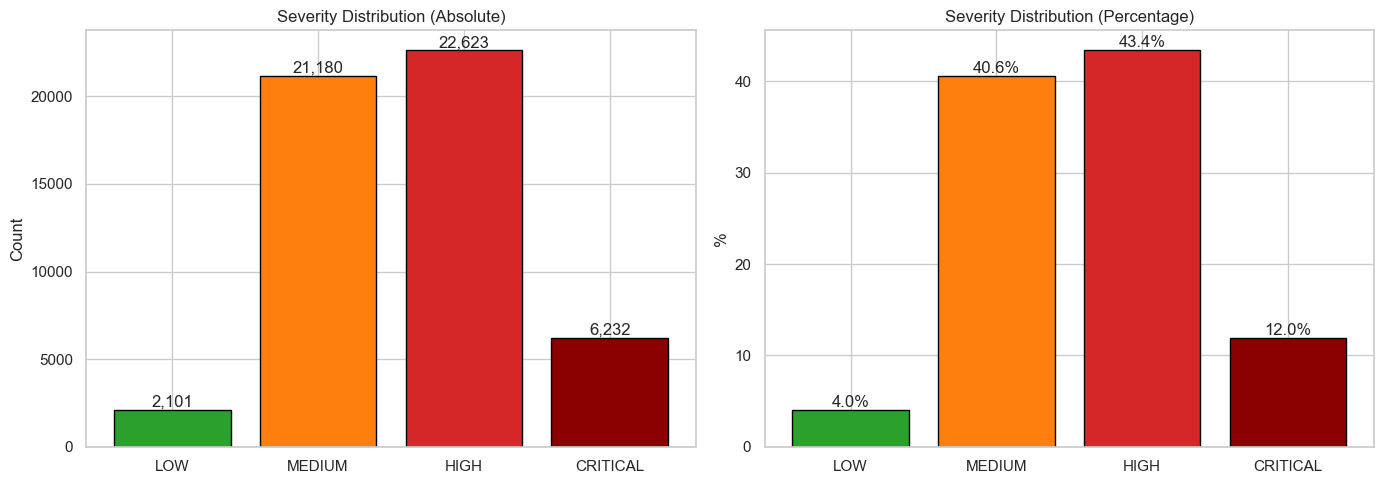

severity
LOW          2101
MEDIUM      21180
HIGH        22623
CRITICAL     6232


In [4]:
sev_order = ['LOW', 'MEDIUM', 'HIGH', 'CRITICAL']
sev_counts = df['severity'].value_counts().reindex(sev_order).fillna(0).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = ['#2ca02c', '#ff7f0e', '#d62728', '#8b0000']
axes[0].bar(sev_order, sev_counts.values, color=colors, edgecolor='black')
axes[0].set_title('Severity Distribution (Absolute)')
axes[0].set_ylabel('Count')
for i, v in enumerate(sev_counts.values):
    axes[0].text(i, v, f'{v:,}', ha='center', va='bottom')

pcts = sev_counts / sev_counts.sum() * 100
axes[1].bar(sev_order, pcts.values, color=colors, edgecolor='black')
axes[1].set_title('Severity Distribution (Percentage)')
axes[1].set_ylabel('%')
for i, v in enumerate(pcts.values):
    axes[1].text(i, v, f'{v:.1f}%', ha='center', va='bottom')

plt.tight_layout()
plt.savefig(EDA_DIR / '01_severity_distribution.png', dpi=120)
plt.show()
print(sev_counts.to_string())

## Step 4 — Relevance Distribution

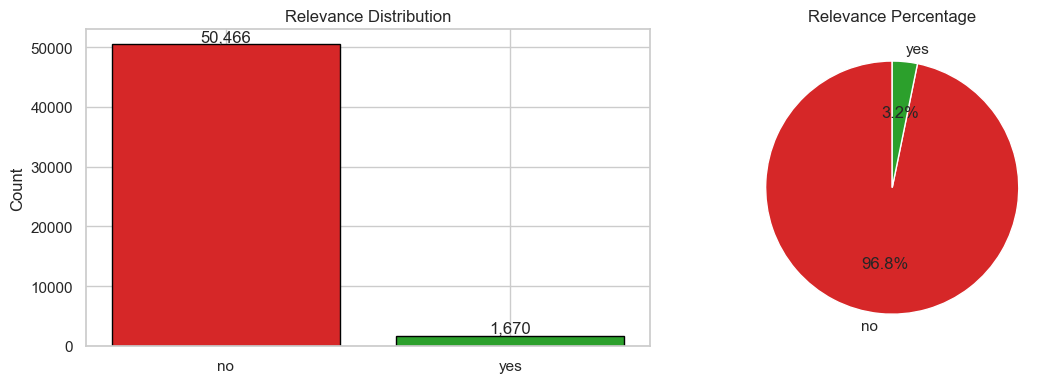

Imbalance ratio: 30.2:1 (no:yes)


In [5]:
rel_counts = df['relevant'].value_counts(dropna=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

colors = ['#d62728' if x == 'no' else '#2ca02c' if x == 'yes' else '#888888' for x in rel_counts.index]
axes[0].bar([str(x) for x in rel_counts.index], rel_counts.values, color=colors, edgecolor='black')
axes[0].set_title('Relevance Distribution')
axes[0].set_ylabel('Count')
for i, v in enumerate(rel_counts.values):
    axes[0].text(i, v, f'{v:,}', ha='center', va='bottom')

axes[1].pie(rel_counts.values, labels=[str(x) for x in rel_counts.index],
            autopct='%1.1f%%', colors=colors, startangle=90)
axes[1].set_title('Relevance Percentage')

plt.tight_layout()
plt.savefig(EDA_DIR / '02_relevance_distribution.png', dpi=120)
plt.show()

if 'yes' in rel_counts.index and 'no' in rel_counts.index:
    ratio = rel_counts['no'] / rel_counts['yes']
    print(f'Imbalance ratio: {ratio:.1f}:1 (no:yes)')

## Step 5 — CVSS Score Distribution

CVSS valid: 50,977 / 52,136
Mean: 6.96  Median: 7.20


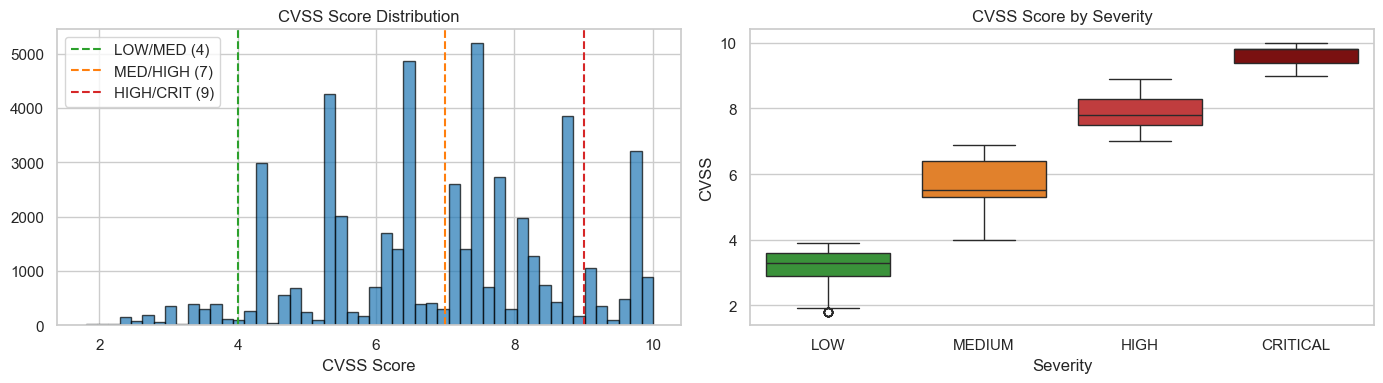

In [6]:
cvss = pd.to_numeric(df['cvss_score'], errors='coerce').dropna()
print(f'CVSS valid: {len(cvss):,} / {len(df):,}')
print(f'Mean: {cvss.mean():.2f}  Median: {cvss.median():.2f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(cvss, bins=50, color='#1f77b4', edgecolor='black', alpha=0.7)
axes[0].axvline(4.0, color='#2ca02c', linestyle='--', label='LOW/MED (4)')
axes[0].axvline(7.0, color='#ff7f0e', linestyle='--', label='MED/HIGH (7)')
axes[0].axvline(9.0, color='#d62728', linestyle='--', label='HIGH/CRIT (9)')
axes[0].set_title('CVSS Score Distribution')
axes[0].set_xlabel('CVSS Score')
axes[0].legend()

sns.boxplot(x=df['severity'], y=pd.to_numeric(df['cvss_score'], errors='coerce'),
            order=sev_order, palette=['#2ca02c', '#ff7f0e', '#d62728', '#8b0000'], ax=axes[1])
axes[1].set_title('CVSS Score by Severity')
axes[1].set_xlabel('Severity')
axes[1].set_ylabel('CVSS')

plt.tight_layout()
plt.savefig(EDA_DIR / '03_cvss_distribution.png', dpi=120)
plt.show()

## Step 6 — Sentence Length Distribution

count    52136.0
mean        60.2
std         35.3
min          4.0
25%         34.0
50%         53.0
75%         78.0
max        200.0


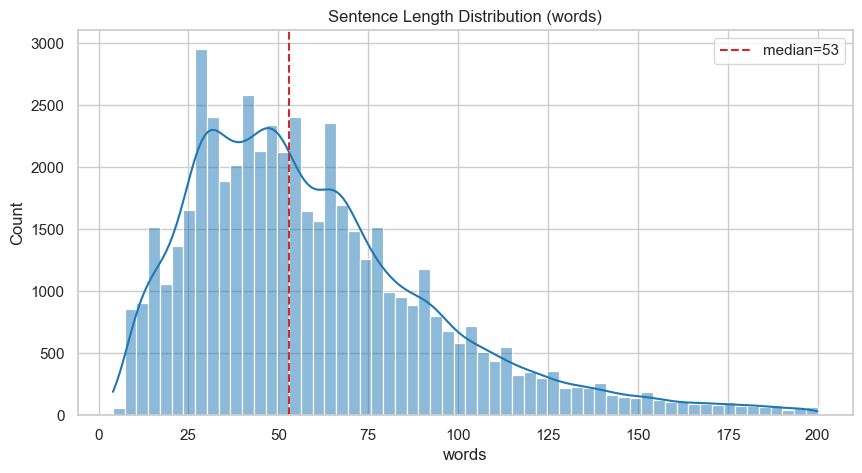

In [7]:
df['_length'] = df['sentence_text'].astype(str).str.split().str.len()
print(df['_length'].describe().round(1).to_string())

plt.figure(figsize=(10, 5))
sns.histplot(df['_length'], bins=60, kde=True, color='#1f77b4')
plt.axvline(df['_length'].median(), color='#d62728', linestyle='--',
            label=f'median={df["_length"].median():.0f}')
plt.title('Sentence Length Distribution (words)')
plt.xlabel('words')
plt.legend()
plt.savefig(EDA_DIR / '04_length_distribution.png', dpi=120)
plt.show()

## Step 7 — ATT&CK Technique Distribution

Rows with ATT&CK: 1,159
Distinct techniques: 70


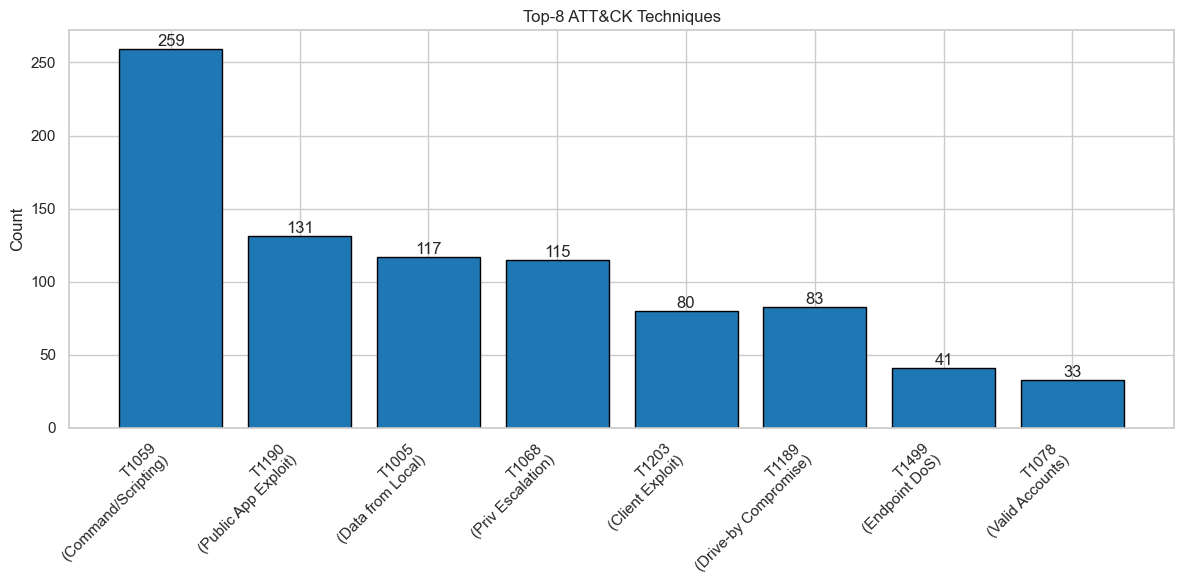

parent
T1059    259
T1190    131
T1005    117
T1068    115
T1203     80
T1189     83
T1499     41
T1078     33


In [8]:
_att_mask = df['techniques'].astype(str).str.contains(r'T\d', na=False)
_att_df = df[_att_mask].copy()
_att_df['parent'] = _att_df['techniques'].astype(str).str.split(';').str[0].str.split('.').str[0].str.strip()

print(f'Rows with ATT&CK: {len(_att_df):,}')
print(f'Distinct techniques: {_att_df["parent"].nunique()}')

TOP8 = ['T1059', 'T1190', 'T1005', 'T1068', 'T1203', 'T1189', 'T1499', 'T1078']
_top8_counts = _att_df['parent'].value_counts().reindex(TOP8).fillna(0).astype(int)

ATTACK_NAMES = {
    'T1059': 'Command/Scripting',
    'T1190': 'Public App Exploit',
    'T1005': 'Data from Local',
    'T1068': 'Priv Escalation',
    'T1203': 'Client Exploit',
    'T1189': 'Drive-by Compromise',
    'T1499': 'Endpoint DoS',
    'T1078': 'Valid Accounts',
}

plt.figure(figsize=(12, 6))
labels = [f'{t}\n({ATTACK_NAMES[t]})' for t in TOP8]
plt.bar(labels, _top8_counts.values, color='#1f77b4', edgecolor='black')
plt.title('Top-8 ATT&CK Techniques')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
for i, v in enumerate(_top8_counts.values):
    plt.text(i, v, str(v), ha='center', va='bottom')
plt.tight_layout()
plt.savefig(EDA_DIR / '05_attack_distribution.png', dpi=120)
plt.show()
print(_top8_counts.to_string())

## Step 8 — Temporal Distribution

Rows with date: 50,977
Range: 2026-01-03 to 2026-09-06


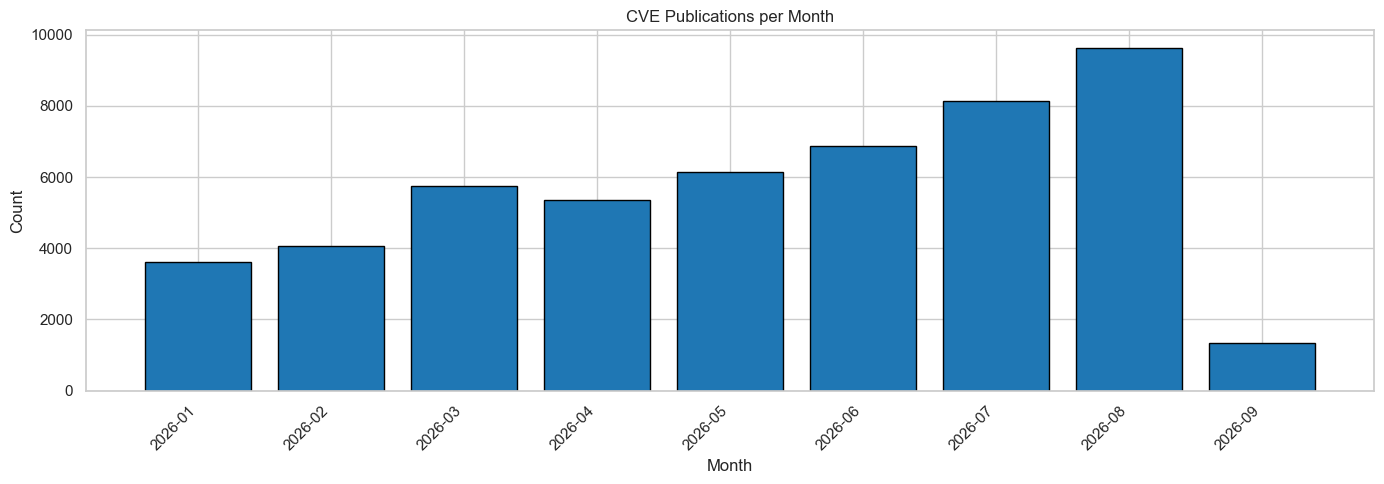

In [9]:
df['_date'] = pd.to_datetime(df['published'], errors='coerce')
_with_date = df[df['_date'].notna()]

if len(_with_date) > 0:
    print(f'Rows with date: {len(_with_date):,}')
    print(f'Range: {_with_date["_date"].min().date()} to {_with_date["_date"].max().date()}')

    _with_date['_month'] = _with_date['_date'].dt.to_period('M').astype(str)
    _month_counts = _with_date['_month'].value_counts().sort_index()

    plt.figure(figsize=(14, 5))
    plt.bar(range(len(_month_counts)), _month_counts.values, color='#1f77b4', edgecolor='black')
    plt.xticks(range(len(_month_counts)), _month_counts.index, rotation=45, ha='right')
    plt.title('CVE Publications per Month')
    plt.xlabel('Month')
    plt.ylabel('Count')
    plt.tight_layout()
    plt.savefig(EDA_DIR / '06_temporal_distribution.png', dpi=120)
    plt.show()
else:
    print('No dates')

## Step 9 — Top CWEs

Total CWE mentions: 58,110


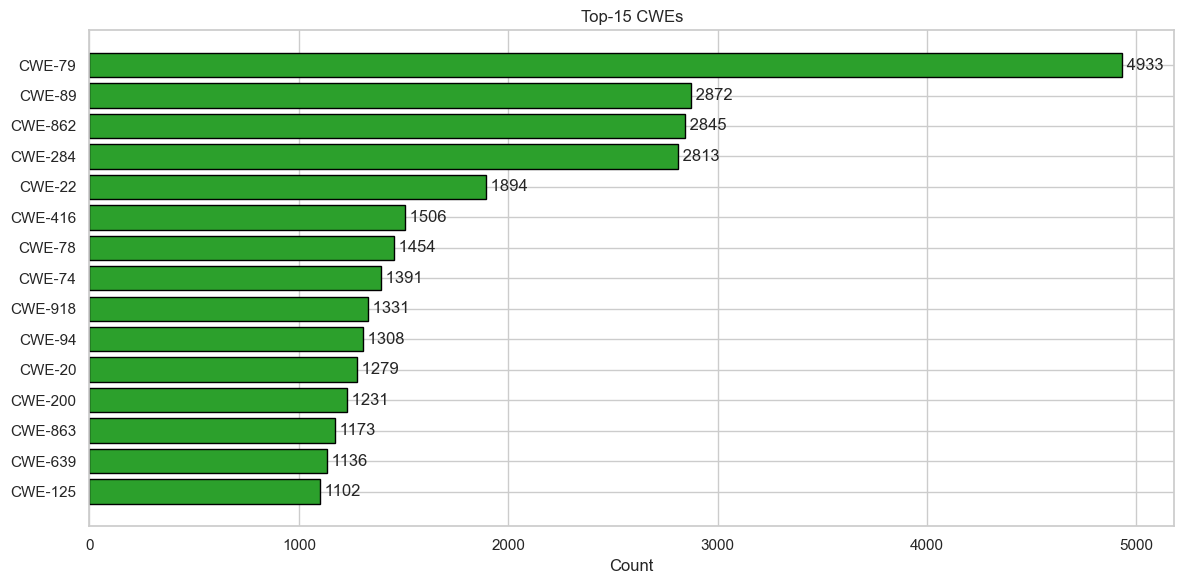

In [10]:
_cwe_flat = df['cwe_ids'].dropna().astype(str).str.strip()
_cwe_flat = _cwe_flat[_cwe_flat.str.len() > 0]
_cwe_items = _cwe_flat.str.split(';').explode().str.strip()
_cwe_items = _cwe_items[_cwe_items.str.startswith('CWE-')]

print(f'Total CWE mentions: {len(_cwe_items):,}')
_top_cwe = _cwe_items.value_counts().head(15)

plt.figure(figsize=(12, 6))
plt.barh(range(len(_top_cwe)), _top_cwe.values, color='#2ca02c', edgecolor='black')
plt.yticks(range(len(_top_cwe)), _top_cwe.index)
plt.gca().invert_yaxis()
plt.title('Top-15 CWEs')
plt.xlabel('Count')
for i, v in enumerate(_top_cwe.values):
    plt.text(v, i, f' {v}', va='center')
plt.tight_layout()
plt.savefig(EDA_DIR / '07_top_cwes.png', dpi=120)
plt.show()

## Step 10 — EPSS Distribution

EPSS valid: 52,050
Mean: 0.0137  Median: 0.0037


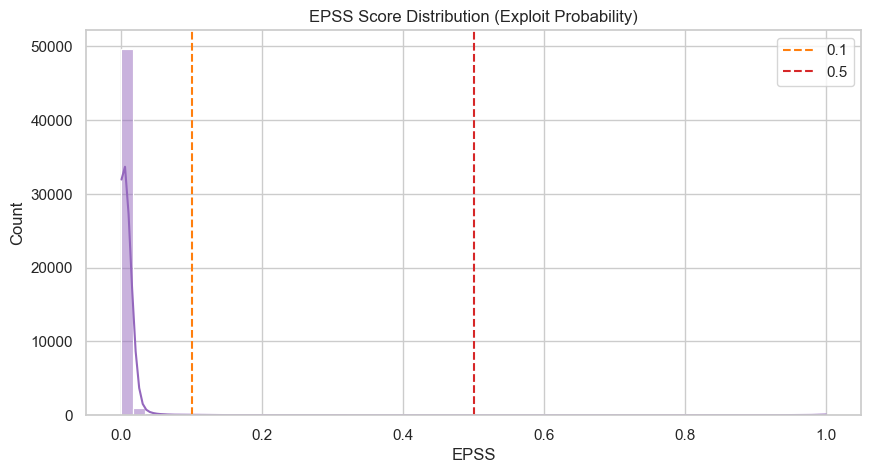

In [11]:
_epss = pd.to_numeric(df['epss'], errors='coerce').dropna()
print(f'EPSS valid: {len(_epss):,}')
print(f'Mean: {_epss.mean():.4f}  Median: {_epss.median():.4f}')

plt.figure(figsize=(10, 5))
sns.histplot(_epss, bins=60, kde=True, color='#9467bd')
plt.axvline(0.1, color='#ff7f0e', linestyle='--', label='0.1')
plt.axvline(0.5, color='#d62728', linestyle='--', label='0.5')
plt.title('EPSS Score Distribution (Exploit Probability)')
plt.xlabel('EPSS')
plt.legend()
plt.savefig(EDA_DIR / '08_epss_distribution.png', dpi=120)
plt.show()

## Step 11 — Severity × Source

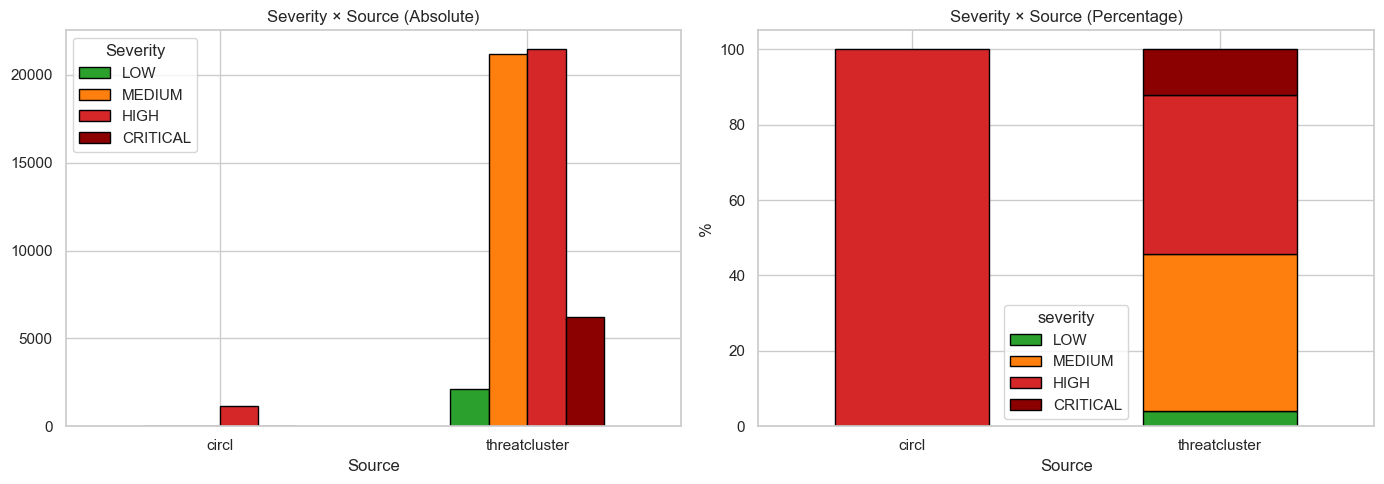

In [12]:
_ct = pd.crosstab(df['source'], df['severity']).reindex(columns=sev_order, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

_ct.plot(kind='bar', ax=axes[0], color=['#2ca02c', '#ff7f0e', '#d62728', '#8b0000'], edgecolor='black')
axes[0].set_title('Severity × Source (Absolute)')
axes[0].set_xlabel('Source')
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(title='Severity')

_ct_pct = _ct.div(_ct.sum(axis=1), axis=0) * 100
_ct_pct.plot(kind='bar', stacked=True, ax=axes[1],
             color=['#2ca02c', '#ff7f0e', '#d62728', '#8b0000'], edgecolor='black')
axes[1].set_title('Severity × Source (Percentage)')
axes[1].set_xlabel('Source')
axes[1].set_ylabel('%')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig(EDA_DIR / '09_severity_by_source.png', dpi=120)
plt.show()

## Step 12 — Correlation Matrix

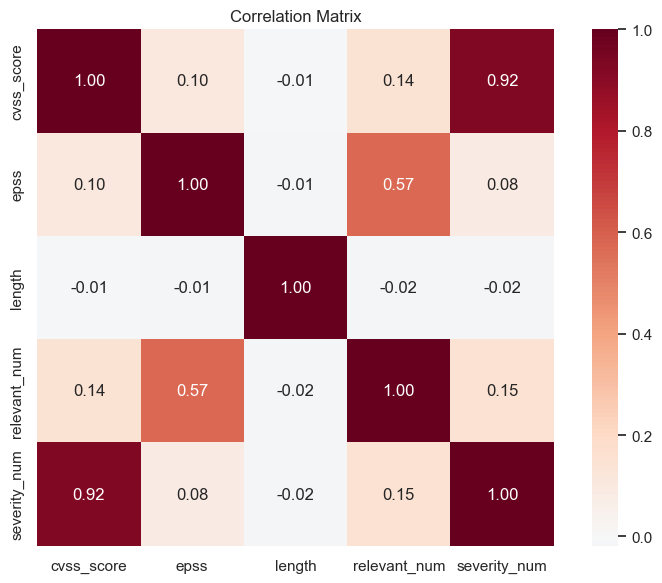

In [13]:
_num_df = pd.DataFrame({
    'cvss_score': pd.to_numeric(df['cvss_score'], errors='coerce'),
    'epss': pd.to_numeric(df['epss'], errors='coerce'),
    'length': df['sentence_text'].astype(str).str.split().str.len(),
    'relevant_num': (df['relevant'] == 'yes').astype(int),
    'severity_num': df['severity'].map({'LOW': 0, 'MEDIUM': 1, 'HIGH': 2, 'CRITICAL': 3}),
})
_corr = _num_df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(_corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, square=True)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.savefig(EDA_DIR / '10_correlation_matrix.png', dpi=120)
plt.show()

## Step 13 — Top CWE Families by Severity

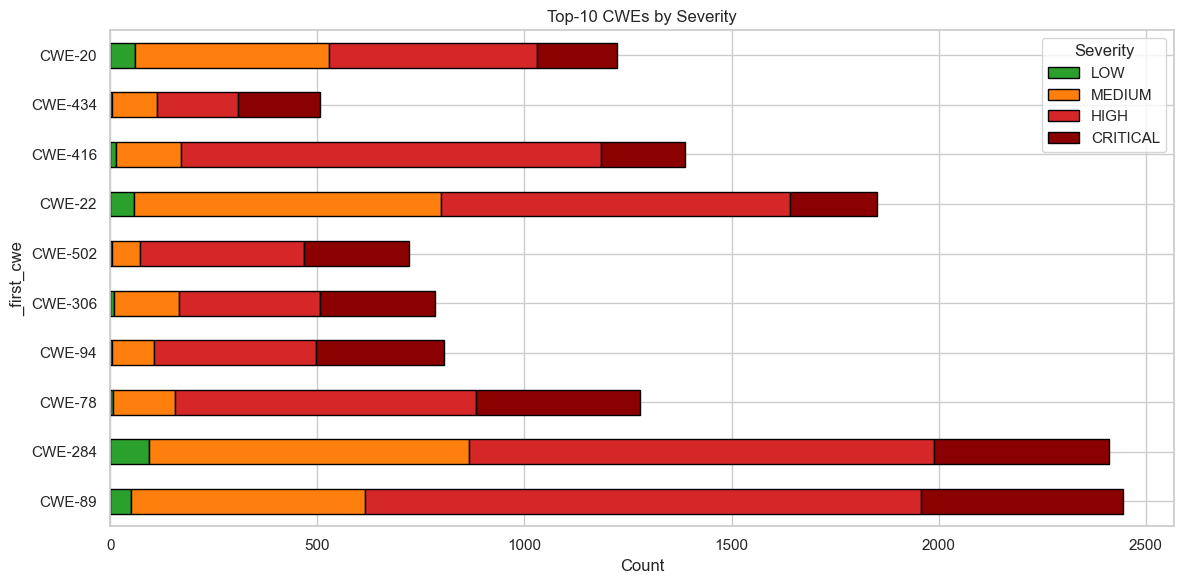

In [14]:
_df_cwe = df.copy()
_df_cwe['_first_cwe'] = _df_cwe['cwe_ids'].astype(str).str.split(';').str[0].str.strip()
_df_cwe = _df_cwe[_df_cwe['_first_cwe'].str.startswith('CWE-', na=False)]

_top_cwe_by_sev = _df_cwe.groupby(['_first_cwe', 'severity']).size().unstack(fill_value=0)
_top_cwe_by_sev = _top_cwe_by_sev.reindex(columns=sev_order, fill_value=0)
_top_cwe_by_sev = _top_cwe_by_sev.sort_values('CRITICAL', ascending=False).head(10)

plt.figure(figsize=(12, 6))
_top_cwe_by_sev.plot(kind='barh', stacked=True,
                     color=['#2ca02c', '#ff7f0e', '#d62728', '#8b0000'],
                     edgecolor='black', ax=plt.gca())
plt.title('Top-10 CWEs by Severity')
plt.xlabel('Count')
plt.legend(title='Severity')
plt.tight_layout()
plt.savefig(EDA_DIR / '11_cwe_by_severity.png', dpi=120)
plt.show()

## Step 14 — EDA Summary Report

In [15]:
print('=' * 60)
print('EDA SUMMARY')
print('=' * 60)
print(f'Total rows            : {len(df):,}')
print(f'Unique CVEs           : {df["cve_id"].nunique():,}')
print(f'Sources               : {df["source"].nunique()}')
print(f'\nSeverity distribution:')
for s in sev_order:
    n = (df['severity'] == s).sum()
    pct = n / len(df) * 100
    print(f'  {s:10s}: {n:>7,}  ({pct:>5.1f}%)')
print(f'\nBinary (relevant):')
for r in ['yes', 'no']:
    n = (df['relevant'] == r).sum()
    pct = n / len(df) * 100
    print(f'  {r:10s}: {n:>7,}  ({pct:>5.1f}%)')
_att_count = df['techniques'].astype(str).str.contains(r'T\d', na=False).sum()
print(f'\nATT&CK:')
print(f'  Rows with ATT&CK     : {_att_count:,}')
print(f'  Top-8 total          : {_top8_counts.sum():,}')
print(f'\nTemporal:')
print(f'  Valid dates          : {_with_date.shape[0]:,}')
if _with_date.shape[0] > 0:
    print(f'  Range                : {_with_date["_date"].min().date()} to {_with_date["_date"].max().date()}')
print(f'\nNumeric:')
print(f'  CVSS mean            : {cvss.mean():.2f}')
print(f'  EPSS mean            : {_epss.mean():.4f}')
print('=' * 60)

EDA SUMMARY
Total rows            : 52,136
Unique CVEs           : 52,136
Sources               : 2

Severity distribution:
  LOW       :   2,101  (  4.0%)
  MEDIUM    :  21,180  ( 40.6%)
  HIGH      :  22,623  ( 43.4%)
  CRITICAL  :   6,232  ( 12.0%)

Binary (relevant):
  yes       :   1,670  (  3.2%)
  no        :  50,466  ( 96.8%)

ATT&CK:
  Rows with ATT&CK     : 1,159
  Top-8 total          : 859

Temporal:
  Valid dates          : 50,977
  Range                : 2026-01-03 to 2026-09-06

Numeric:
  CVSS mean            : 6.96
  EPSS mean            : 0.0137


## Step 15 — Thesis-Ready EDA Paragraph

In [16]:
_severity_txt = ', '.join([f'{s}={sev_counts[s]:,} ({sev_counts[s]/len(df)*100:.1f}%)' for s in sev_order])
_rel_yes = (df['relevant'] == 'yes').sum()

summary = (
    f'The cleaned corpus contains {len(df):,} CVE records from '
    f'{df["cve_id"].nunique():,} unique CVEs. '
    f'Severity distribution: {_severity_txt}. '
    f'Only {_rel_yes:,} records ({_rel_yes/len(df)*100:.1f}%) are labeled relevant, '
    f'reflecting severe class imbalance. '
    f'The dataset contains {_att_count:,} ATT&CK-labeled records across '
    f'{_att_df["parent"].nunique()} distinct techniques, with the top-8 '
    f'accounting for {_top8_counts.sum():,} records. '
    f'CVSS scores average {cvss.mean():.2f} (range {cvss.min():.1f}–{cvss.max():.1f}), '
    f'and EPSS scores average {_epss.mean():.4f}. '
    f'Temporal coverage spans {_with_date["_date"].min().date()} to '
    f'{_with_date["_date"].max().date()} '
    f'({_with_date["_date"].dt.to_period("M").nunique()} months).'
)
print(summary)

with open(EDA_DIR / 'eda_summary.txt', 'w') as f:
    f.write(summary)
print(f'\n✅ Saved summary: {EDA_DIR / "eda_summary.txt"}')

The cleaned corpus contains 52,136 CVE records from 52,136 unique CVEs. Severity distribution: LOW=2,101 (4.0%), MEDIUM=21,180 (40.6%), HIGH=22,623 (43.4%), CRITICAL=6,232 (12.0%). Only 1,670 records (3.2%) are labeled relevant, reflecting severe class imbalance. The dataset contains 1,159 ATT&CK-labeled records across 70 distinct techniques, with the top-8 accounting for 859 records. CVSS scores average 6.96 (range 1.8–10.0), and EPSS scores average 0.0137. Temporal coverage spans 2026-01-03 to 2026-09-06 (9 months).

✅ Saved summary: d:\Projects\done\thesis\cyber_threat_classification_n_emerging_threat_detection\results\02_eda\eda_summary.txt


## Step 16 — Preview Dataset

In [17]:
try:
    import framedisplay as fd
    fd.frame_display(df.head(100))
except ImportError:
    print('Install: pip install framedisplay')
    df.head(20)

,cve_id,sentence_text,source,published,relevant,severity,cvss_score,techniques,primary_tech,tech_name,cwe_ids,in_kev,kev_ransomware,epss,_length,_date
0,CVE-2026-86151,A vulnerability was detected in Tenda CP3 27.5.57.101. The affected element is the function sub_2F77E8 of the file Apis/system.c of the component Network Configuration Management. Performing a manipulation results in os command injection. The attack may be initiated remotely.,threatcluster,2026-09-06,no,CRITICAL,9.1,null,null,null,CWE-77;CWE-78,False,null,0.02945,39,2026-09-06 00:00:00
1,CVE-2026-86179,A flaw has been found in code-projects Daily Expense Manager 1.0. Affected is an unknown function of the file /Daily-Expense-Manager/exp_ak.sql of the component Database Backup Handler. Executing a manipulation can lead to information disclosure. It is possible to launch the attack remotely. The exploit has been published and may be used.,threatcluster,2026-09-06,no,MEDIUM,5.3,null,null,null,CWE-200;CWE-284,False,null,0.00532,51,2026-09-06 00:00:00
2,CVE-2026-86164,A security flaw has been discovered in itsourcecode Sales and Inventory System 1.0. Affected is an unknown function of the file /pages/trans_view.php. The manipulation of the argument ID results in sql injection. The attack may be performed from remote. The exploit has been released to the public and may be used for attacks.,threatcluster,2026-09-06,no,MEDIUM,6.3,null,null,null,CWE-74;CWE-89,False,null,0.00333,53,2026-09-06 00:00:00
3,CVE-2026-86166,A vulnerability was determined in Tenda HG10 300001138. This issue affects the function formWanRedirect of the file /boaform/formWanRedirect of the component Boa Web Server. Executing a manipulation of the argument if can lead to buffer overflow. The attack may be launched remotely. The exploit has been publicly disclosed and may be utilized.,threatcluster,2026-09-06,no,HIGH,8.8,null,null,null,CWE-119;CWE-120,False,null,0.00854,52,2026-09-06 00:00:00
4,CVE-2026-86163,A vulnerability was identified in itsourcecode Sales and Inventory System 1.0. This impacts an unknown function of the file /pages/pro_del.php. The manipulation of the argument ID leads to sql injection. The attack is possible to be carried out remotely. The exploit is publicly available and might be used.,threatcluster,2026-09-06,no,MEDIUM,6.3,null,null,null,CWE-74;CWE-89,False,null,0.00333,48,2026-09-06 00:00:00
5,CVE-2026-86180,A vulnerability has been found in code-projects Task Management System In PHP 1.0. Affected by this vulnerability is an unknown functionality of the file /index.php of the component Login. The manipulation of the argument email leads to sql injection. The attack can be initiated remotely. The exploit has been disclosed to the public and may be used.,threatcluster,2026-09-06,no,HIGH,7.3,null,null,null,CWE-74;CWE-89,False,null,0.00431,57,2026-09-06 00:00:00
6,CVE-2026-86153,A vulnerability has been found in Tenda CP3 27.5.57.101. This affects the function CRedirServer::SetRedirectEnable of the file Functions/Redirect.cpp. The manipulation leads to improper privilege management. Remote exploitation of the attack is possible.,threatcluster,2026-09-06,no,CRITICAL,9.1,null,null,null,CWE-266;CWE-269,False,null,0.00715,32,2026-09-06 00:00:00
7,CVE-2026-86165,A vulnerability was found in Tenda HG10 300001138. This vulnerability affects the function formURL of the file /boaform/admin/formURL. Performing a manipulation of the argument Keywd/urlFQDN results in buffer overflow. The attack may be initiated remotely. The exploit has been made public and could be used.,threatcluster,2026-09-06,no,CRITICAL,9.8,null,null,null,CWE-119;CWE-120,False,null,0.01132,45,2026-09-06 00:00:00
8,CVE-2026-18056,"The HivePress Authentication plugin for WordPress is vulnerable to Authentication Bypass via the access_token parameter in all versions up to, and including, 1.1.4. This is due to the authenticate_user function's Facebook authenticator resolving third-party identity by forwarding the attack